# 重現 2025 龍舟專題

本專案目的在於重現學長的 Yolo 分支的結果，重現方法與差異都會在各個小節指出。

# 前處理

- FPS=5 抽幀 + 統計
- 輸出：`frames/<video_id>/<video_id>_%06d.jpg`、`manifest.csv`、`video_stats.csv`

預期步驟：

1. 使用 coco pretrain weight 的 RF-DETR 自動產生划槳位置資訊
2. 基於那些資訊/標注，建立 Automated Label Set
    - Automated Label Set: {x, y, width, height, class_name = paddle}
3. YOLOv11s pretrain 基於 Automated Label Set 進行訓練

問題：
- 不太清楚 RF-DETR 如何自動產生划槳位置資訊，懷疑報告中對這個步驟描述有一些偏差。
- 影片數量他們 29 部 vs 我們 31 部，不確定哪兩個影片沒有用到。
- 根據專題最終報告 §（五）資料庫來源與建立 提到
    FPS=5 的取樣結果總共獲得 5,420 張影像，其中 2,710（一半）張影像由後續的半監督學習與偽標籤（pseudo-label）生成。 如果以 FPS=5 取樣實際 31 部影片 32,868 張圖片，與報告中的 5,420 落差巨大，應該是後續有對資料質量做篩選。

我們的步驟：

1. 透過 Yolov11s 先學習 300 張人工審核過的高質量資料集。(300 是 train 的規模，不是整體)
2. 透過該資料學習後，產生更多偽標籤
3. 人工審核偽標籤的質量，進行微調整

## Config

In [1]:
import json, math, re, shutil, subprocess, sys, tempfile, platform
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    IN_COLAB = True
except:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Colab Notebooks/大三專題_備選題目_車禍')
else:
    ROOT = Path.cwd()

VIDEOS_DIR = ROOT / "videos"
FRAMES_DIR = ROOT / "frames"
LABELS_DIR = ROOT / "labels"
MANIFEST_CSV = ROOT / "manifest.csv"
STATS_CSV = ROOT / "video_stats.csv"

FPS = 5
JPEG_Q = 2                             # NTOE: 高畫質
REPORT_TOTAL = 5420                    # 報告中的總張數（29 部）
REPORT_VIDEOS = 29

Mounted at /content/drive


In [2]:
assert VIDEOS_DIR.exists(), f"資料夾不存在: {VIDEOS_DIR}"
assert LABELS_DIR.exists(), f"資料夾不存在: {LABELS_DIR}"

## 環境設定

In [3]:
ffmpeg_ver = subprocess.run(["ffmpeg", "-version"], capture_output=True, text=True).stdout.splitlines()[0]
print("ffmpeg  :", ffmpeg_ver)
print("python  :", platform.python_version())
print("opencv  :", cv2.__version__)
print("pandas  :", pd.__version__)

ffmpeg  : ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
python  : 3.13.16
opencv  : 4.14.0
pandas  : 2.2.3


In [4]:
!nvidia-smi

Sun Nov 22 12:52:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
import os, random
import numpy as np
import torch

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)                  # 只影響之後啟動的子行程；目前這個 Python 的 hash seed 在啟動時就定了
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"         # 確定性 cuBLAS 需要，必須在第一次用 CUDA 之前設定（否則要重啟 runtime）

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False                    # benchmark 會依速度選演算法，結果可能不同
torch.use_deterministic_algorithms(True, warn_only=True)  # 沒有確定性實作的運算只警告，不中斷


def seed_worker(worker_id):
    # DataLoader 的每個 worker 是獨立行程，numpy / random 要各自重設
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


g = torch.Generator()
g.manual_seed(SEED)                                       # 傳給 DataLoader(generator=g, worker_init_fn=seed_worker)
print("seed    :", SEED, "| torch:", torch.__version__, "| cuda:", torch.cuda.is_available())

seed    : 42 | torch: 2.14.1+cu130 | cuda: True


## 獲取每個影片的資訊

拍攝設備有可能不同，在處理影片時應該確保相關屬性（如解析度、總共張數等）。

In [6]:
# videos = sorted(VIDEOS_DIR.glob("*.mp4"))
# print(videos[:min(3, len(videos))])
# r = subprocess.run(
#     ["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_streams", "-show_format", "-of", "json", str("videos/B04鍾祈恩.mp4")],
#     capture_output=True, text=True, check=True)
# d = json.loads(r.stdout)
# s = d["streams"][0]
# print(json.dumps(s, indent=2))

In [7]:
# 拍攝設備有可能不同，在處理影片時應該確保相關屬性（如解析度）

def probe(path):
    r = subprocess.run(
        ["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_streams", "-show_format", "-of", "json", str(path)],
        capture_output=True, text=True, check=True)
    d = json.loads(r.stdout)
    s = d["streams"][0]
    num, den = map(int, s["avg_frame_rate"].split("/"))
    return dict(
        width=s["width"], height=s["height"],
        fps_avg=round(num / den, 3),
        duration_s=round(float(d["format"]["duration"]), 3),
        size_mb=round(path.stat().st_size / 2**20, 1),
    )

videos = sorted(VIDEOS_DIR.glob("*.mp4"))
rows = []
for p in videos:
    vid = re.match(r"[A-Z]\d+", p.stem).group(0)
    rows.append(dict(video_id=vid, source_file=p.name, group=vid[0], **probe(p)))
stats = pd.DataFrame(rows).sort_values("video_id").reset_index(drop=True)
assert stats.video_id.is_unique and len(stats) == 31, len(stats)
stats["expected_frames"] = (stats.duration_s * FPS).apply(math.floor)
print(len(stats), "部影片，總長", round(stats.duration_s.sum()), "秒")
display(stats.drop(columns="source_file"))   # ai 不希望顯示姓名，保護隱私

31 部影片，總長 6574 秒


,video_id,group,width,height,fps_avg,duration_s,size_mb,expected_frames
0,A01,A,1280,720,30.001,204.490,119.9,1022
1,A02,A,1920,1080,30.023,183.695,120.3,918
2,A04,A,1920,1080,30.023,190.090,125.7,950
3,A05,A,1920,1080,30.023,221.233,143.0,1106
4,A06,A,1920,1080,30.023,220.833,145.6,1104
5,A07,A,1920,1080,30.022,182.030,119.5,910
6,A09,A,1920,1080,30.023,210.342,131.8,1051
7,B02,B,1920,1080,30.023,201.715,140.6,1008
8,B03,B,1280,720,30.003,202.481,108.6,1012
9,B04,B,1920,1080,30.023,194.687,129.2,973


In [8]:
print(f"total frame: {sum(stats["expected_frames"])}")

total frame: 32853


## 抽幀

依照學長姊的報告，已 FPS=5 的速度取幀。

In [9]:
# 刪掉 .done 可以重來

def extract(row):
    vid = row["video_id"]
    out = FRAMES_DIR / vid
    done = out / ".done"
    tag = f"fps={FPS} q={JPEG_Q}"
    if done.exists() and done.read_text() == tag:
        return "skip"
    if out.exists():
        shutil.rmtree(out)             # 只清自己產生的未完成/舊設定輸出
    out.mkdir(parents=True)
    subprocess.run(
        ["ffmpeg", "-nostdin", "-v", "error", "-i", str(VIDEOS_DIR / row["source_file"]),
         "-an", "-vf", f"fps={FPS}", "-q:v", str(JPEG_Q), "-start_number", "0",
         str(out / f"{vid}_%06d.jpg")],
        check=True)
    done.write_text(tag)
    return "done"

for _, row in stats.iterrows():
    print(row.video_id, extract(row))

A01 skip
A02 skip
A04 skip
A05 skip
A06 skip
A07 skip
A09 skip
B02 skip
B03 skip
B04 skip
B05 skip
B06 skip
B07 skip
B08 skip
B09 skip
B10 skip
B11 skip
B12 skip
B13 skip
B14 skip
B15 skip
B16 skip
B17 skip
B18 skip
C01 skip
C02 skip
C03 skip
C04 skip
C05 skip
C07 skip
C08 skip


## manifest.csv

In [10]:
# 嘗試解碼每張圖，確保可讀

def read_size(path):
    img = cv2.imread(str(path))
    return None if img is None else img.shape[1::-1]   # (w, h)

# manifest.csv 已存在就跳過（Colab 的 CPU 少，掃 3 萬多張很慢）；要重建就刪掉 manifest.csv
if MANIFEST_CSV.exists():
    print("manifest.csv 已存在，跳過掃描")
else:
    records, bad = [], []
    for vid, src in zip(stats.video_id, stats.source_file):
        files = sorted((FRAMES_DIR / vid).glob("*.jpg"))
        with ThreadPoolExecutor() as ex:
            sizes = list(ex.map(read_size, files))
        for f, sz in zip(files, sizes):
            if sz is None:
                bad.append(f)
                continue
            idx = int(f.stem.rsplit("_", 1)[1])
            records.append(dict(video_id=vid, source_file=src, frame_idx=idx,
                                timestamp_s=idx / FPS,          # 時間戳，一張圖佔用了 5 FPS，所以除回來
                                width=sz[0], height=sz[1], path=f.relative_to(ROOT).as_posix()))
    manifest = pd.DataFrame(records)
    manifest.to_csv(MANIFEST_CSV, index=False)
    print("manifest 列數:", len(manifest), "| 無法解碼:", len(bad))
    assert not bad

manifest.csv 已存在，跳過掃描


In [11]:
manifest = pd.read_csv(MANIFEST_CSV)
display(manifest.drop(columns="source_file"))   # ai 不希望顯示姓名，保護隱私

,video_id,frame_idx,timestamp_s,width,height,path
0,A01,0,0.0,1280,720,frames/A01/A01_000000.jpg
1,A01,1,0.2,1280,720,frames/A01/A01_000001.jpg
2,A01,2,0.4,1280,720,frames/A01/A01_000002.jpg
3,A01,3,0.6,1280,720,frames/A01/A01_000003.jpg
4,A01,4,0.8,1280,720,frames/A01/A01_000004.jpg
...,...,...,...,...,...,...
32861,C08,1194,238.8,1920,1080,frames/C08/C08_001194.jpg
32862,C08,1195,239.0,1920,1080,frames/C08/C08_001195.jpg
32863,C08,1196,239.2,1920,1080,frames/C08/C08_001196.jpg
32864,C08,1197,239.4,1920,1080,frames/C08/C08_001197.jpg


## video_stats.csv

In [12]:
counts = manifest.groupby("video_id").size()
stats["extracted_frames"] = stats.video_id.map(counts).fillna(0).astype(int)
stats["ok"] = (stats.extracted_frames - stats.expected_frames).abs() <= 1   # 表示這個影片相對健康，我們會使用它
stats = stats[["video_id", "source_file", "group", "width", "height", "fps_avg",
               "duration_s", "size_mb", "expected_frames", "extracted_frames", "ok"]]
stats.to_csv(STATS_CSV, index=False)
display(stats.drop(columns="source_file"))   # ai 不希望顯示姓名，保護隱私

,video_id,group,width,height,fps_avg,duration_s,size_mb,expected_frames,extracted_frames,ok
0,A01,A,1280,720,30.001,204.490,119.9,1022,1022,True
1,A02,A,1920,1080,30.023,183.695,120.3,918,918,True
2,A04,A,1920,1080,30.023,190.090,125.7,950,950,True
3,A05,A,1920,1080,30.023,221.233,143.0,1106,1106,True
4,A06,A,1920,1080,30.023,220.833,145.6,1104,1104,True
5,A07,A,1920,1080,30.022,182.030,119.5,910,910,True
6,A09,A,1920,1080,30.023,210.342,131.8,1051,1052,True
7,B02,B,1920,1080,30.023,201.715,140.6,1008,1009,True
8,B03,B,1280,720,30.003,202.481,108.6,1012,1012,True
9,B04,B,1920,1080,30.023,194.687,129.2,973,973,True


## 統計

跟學長姊實際的結果進行比較

In [13]:
total = int(stats.extracted_frames.sum())
summary = pd.DataFrame({
    "影片數": [len(stats), REPORT_VIDEOS],
    "總張數": [total, REPORT_TOTAL],
    "每部平均": [round(total / len(stats), 1), round(REPORT_TOTAL / REPORT_VIDEOS, 1)],
}, index=["本次實際（FPS=5，31 部）", "報告"])
display(summary)
# print(f"本次 / 報告 = {total / REPORT_TOTAL:.2f}x | 預期張數合計 = {int(stats.expected_frames.sum())}")
print("磁碟用量（GB）:", round(sum(f.stat().st_size for f in FRAMES_DIR.rglob("*.jpg")) / 2**30, 2))

,影片數,總張數,每部平均
本次實際（FPS=5，31 部）,31,32866,1060.2
報告,29,5420,186.9


磁碟用量（GB）: 7.09


,videos,frames
group,,
A,7,7062
B,17,17161
C,7,8643


,videos,frames
res,,
1080p,21,21267
720p,10,11599


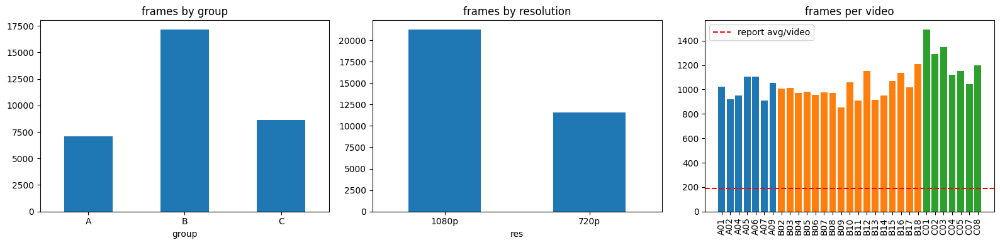

In [14]:
stats["res"] = stats.height.astype(str) + "p"
by_group = stats.groupby("group").agg(videos=("video_id", "size"), frames=("extracted_frames", "sum"))
by_res = stats.groupby("res").agg(videos=("video_id", "size"), frames=("extracted_frames", "sum"))
display(by_group)
display(by_res)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
by_group.frames.plot.bar(ax=ax[0], title="frames by group", rot=0)
by_res.frames.plot.bar(ax=ax[1], title="frames by resolution", rot=0)
colors = stats.group.map({"A": "tab:blue", "B": "tab:orange", "C": "tab:green"})
ax[2].bar(stats.video_id, stats.extracted_frames, color=colors)
ax[2].axhline(REPORT_TOTAL / REPORT_VIDEOS, color="red", ls="--", label="report avg/video")
ax[2].set_title("frames per video"); ax[2].tick_params(axis="x", rotation=90); ax[2].legend()
plt.tight_layout(); plt.show()

## 驗證

In [15]:
# (a) 實際 vs 預期張數
mismatch = stats[~stats.ok]
print("張數不符（超出 ±1）:", mismatch.video_id.tolist())
print("最大偏差:", (stats.extracted_frames - stats.expected_frames).abs().max())

# (b) 所有圖片可解碼：第 5 步已逐張 imread，失敗數 =", len(bad)
# (c) 輸出解析度與影片一致
dims = manifest.groupby("video_id")[["width", "height"]].agg(["min", "max"])
chk = stats.set_index("video_id")
for vid, r in chk.iterrows():
    assert (dims.loc[vid, ("width", "min")], dims.loc[vid, ("width", "max")]) == (r.width, r.width), vid
    assert (dims.loc[vid, ("height", "min")], dims.loc[vid, ("height", "max")]) == (r.height, r.height), vid
print("所有圖片解析度與 video_stats 一致")

張數不符（超出 ±1）: []
最大偏差: 1
所有圖片解析度與 video_stats 一致


## 解析度：720p vs 1080p（縮小到 640）

解析度（影片的寬度）會影響圖片縮放後的結果，從實驗結果來看將圖片縮放到尺寸 640 * 640 不會造成比例上嚴重的失調。
個人認為這不會使的模型的學習困難。

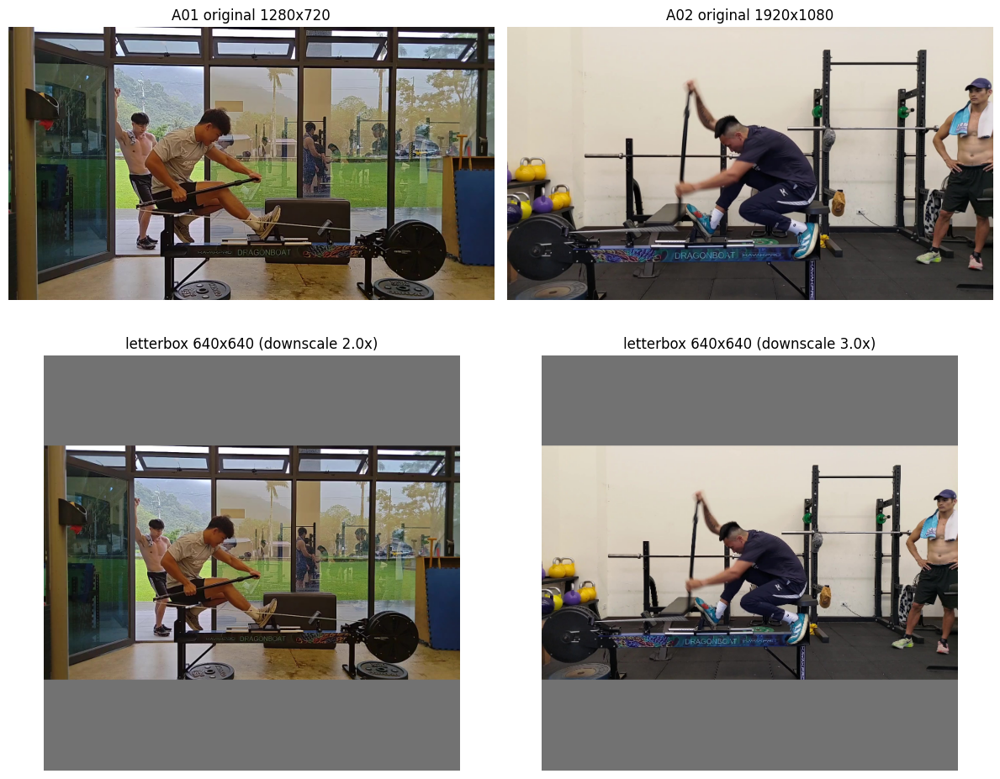

In [16]:
import numpy as np

# 參考：https://www.ultralytics.com/glossary/data-preprocessing#image-preprocessing-for-vision-models
def letterbox(img, size=640):
    # 近似 YOLO 前處理：縮放長邊，短邊以灰色 114 補滿
    h, w = img.shape[:2]
    s = size / max(h, w)
    nw, nh = round(w * s), round(h * s)
    canvas = np.full((size, size, 3), 114, np.uint8)
    top, left = (size - nh) // 2, (size - nw) // 2
    canvas[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    return canvas

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for col, h in enumerate([720, 1080]):
    row = manifest[manifest.height == h].iloc[500]
    img = cv2.imread(str(ROOT / row.path))
    axes[0, col].imshow(img[:, :, ::-1])
    axes[0, col].set_title(f"{row.video_id} original {img.shape[1]}x{img.shape[0]}")
    axes[1, col].imshow(letterbox(img)[:, :, ::-1])
    axes[1, col].set_title(f"letterbox 640x640 (downscale {img.shape[1] / 640:.1f}x)")
for a in axes.ravel():
    a.axis("off")
plt.tight_layout(); plt.show()

## 瀏覽資料

選取五個影片作為預覽，用以預覽影片在 FPS=5 的切割狀態下船槳是否會出現模糊的的影像。
這類影像不應該被當作訓練資料讓 ai 學習。

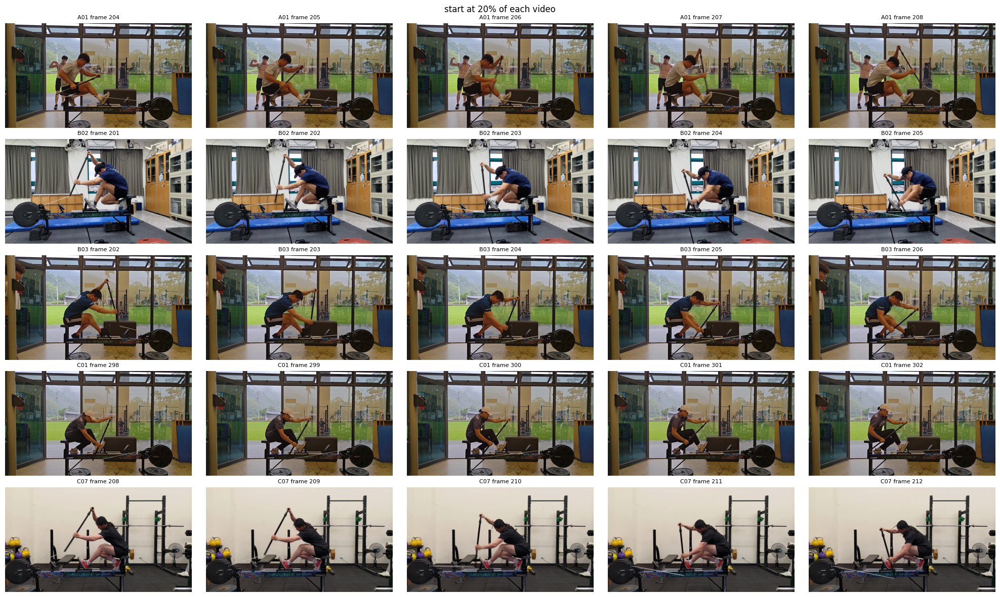

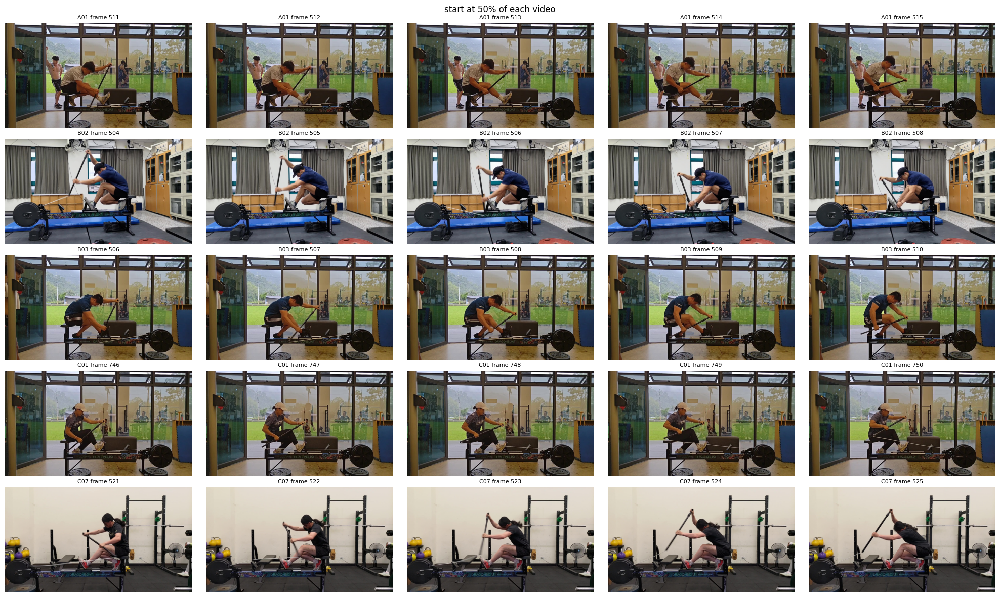

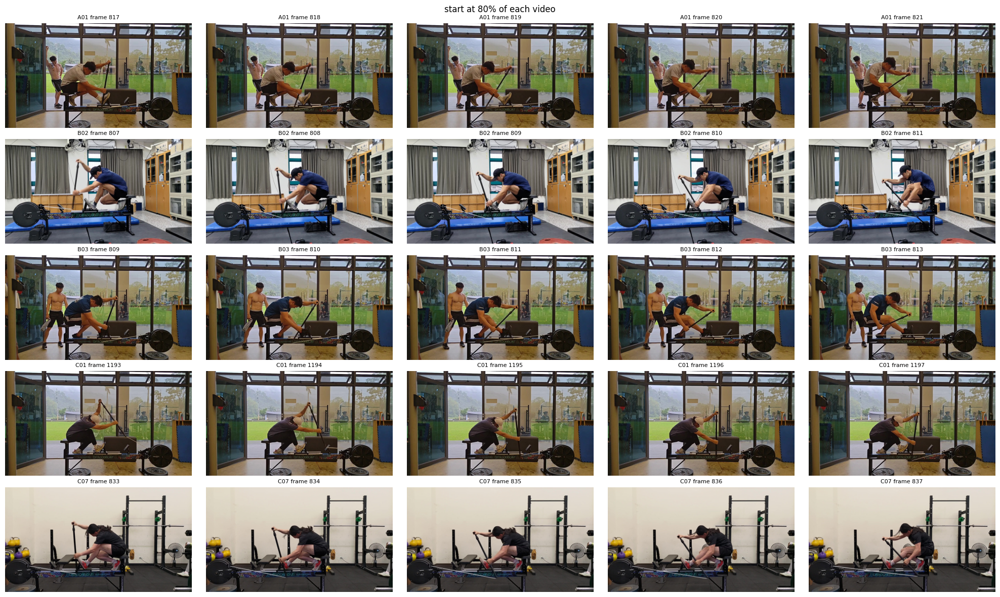

In [17]:
video_id_list = ["A01", "B02", "B03", "C01", "C07"]

assert len(video_id_list) == 5 and stats['video_id'].isin(video_id_list).sum() == 5

# 三張圖：每張的起點為各影片總張數的 20% / 50% / 80%，每部取連續 5 張
start_fracs = [0.2, 0.5, 0.8]
n_frames = 5

for frac in start_fracs:
    # array[video_id][frame]：第 i 列為第 i 部影片，第 j 欄為第 j 張連續影格
    array = []
    for vid in video_id_list:
        v = manifest[manifest.video_id == vid]
        start = int(len(v) * frac)
        array.append([v.iloc[start + j] for j in range(n_frames)])

    fig, axes = plt.subplots(len(video_id_list), n_frames, figsize=(4 * n_frames, 2.4 * len(video_id_list)))
    for i, frames in enumerate(array):
        for j, row in enumerate(frames):
            axes[i, j].imshow(cv2.imread(str(ROOT / row.path))[:, :, ::-1])
            axes[i, j].set_title(f"{row.video_id} frame {row.frame_idx}", fontsize=8)
            axes[i, j].axis("off")
    fig.suptitle(f"start at {frac:.0%} of each video")
    plt.tight_layout(); plt.show()

從解果上來看，間隔 0.2 秒其實動作差異不大。
我希望找到合適的間隔，之後在透過某些傳統算法篩選出動作差異大的圖片：
- hash: 對圖片做編碼，差異大的視為相異度大
- diff: 兩張圖片相減，像素上差距大的視為相異度大
- 人工: 我認為差異很大


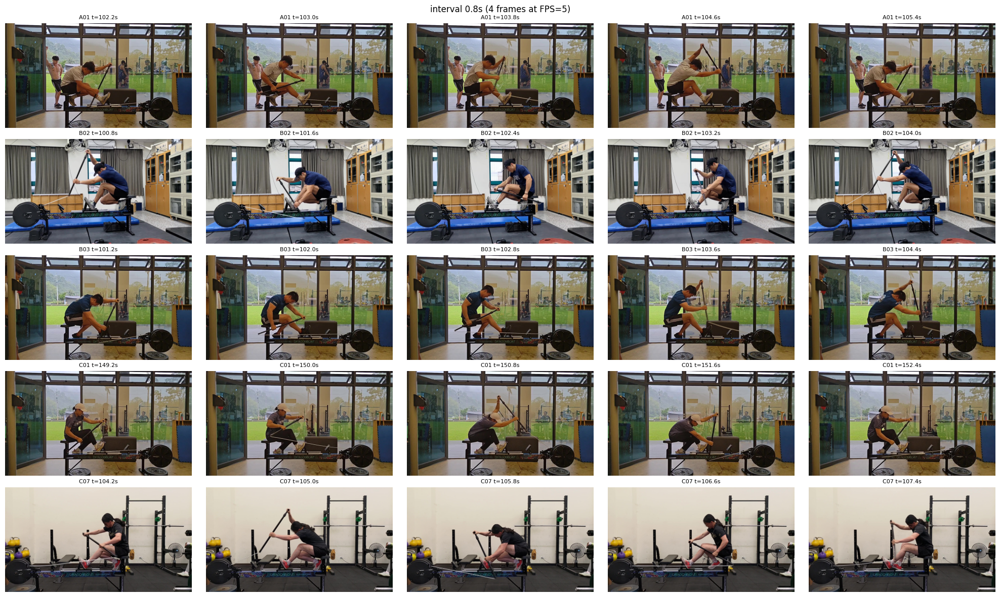

In [18]:
# d_time 表示時間間隔，單位：秒

d_time = 0.8
step = round(d_time * FPS)             # 每隔幾張取一張（以張數計，避開浮點數取餘數的誤差）
assert d_time > 0, "d_time 必須大於 0"
assert math.isclose(step / FPS, d_time), f"必須是 {1/FPS} 的整數倍"

# 以 d_time 為間隔預覽：每部影片從 50% 處起，取 5 張，frame_idx 每次加 step
start_frac = 0.5
n_frames = 5

fig, axes = plt.subplots(len(video_id_list), n_frames, figsize=(4 * n_frames, 2.4 * len(video_id_list)))
for i, vid in enumerate(video_id_list):
    v = manifest[manifest.video_id == vid]
    start = int(len(v) * start_frac)
    for j in range(n_frames):
        row = v.iloc[start + j * step]
        axes[i, j].imshow(cv2.imread(str(ROOT / row.path))[:, :, ::-1])
        axes[i, j].set_title(f"{row.video_id} t={row.timestamp_s:.1f}s", fontsize=8)
        axes[i, j].axis("off")
fig.suptitle(f"interval {d_time}s ({step} frames at FPS={FPS})")
plt.tight_layout(); plt.show()

## 選取策略

好的資料應該長什麼樣子？

- 覆蓋四個動作階段：入水、拉槳、出水、回槳
- 涵蓋 1080p 與 720p
- 場景、性別盡可能平均
- 影像之間的差異盡可能大

壞的資料應該長什麼樣子？（我們要避免）

- 槳不在畫面、被遮擋
- 模糊到人類也很難確定槳的真實位置
- 差異性小，模型可能 overfit

In [19]:
# 窗、草地: A01 B03 B10 B12 B15 B16 B17 C01 C02 C03
# 支架、室內: A02 A04 A05 A06 A07 A09 B11 B13 B14 B18 C04 C05 C07 C08
# 教室、室內: B02 B04 B05 B06 B07 B08 B09

# 沒上衣: A07 A09 B12 B13 B14 B15 B17 B18 (其他都有上衣)
# 特例(多人、不乾淨): A09 B16 B18

ATTRS_CSV = ROOT / "video_attrs.csv"

scenes = {
    "窗草地": "A01 B03 B10 B12 B15 B16 B17 C01 C02 C03",
    "支架室內": "A02 A04 A05 A06 A07 A09 B11 B13 B14 B18 C04 C05 C07 C08",
    "教室室內": "B02 B04 B05 B06 B07 B08 B09",
}
scene_of = {vid: name for name, ids in scenes.items() for vid in ids.split()}
shirtless = set("A07 A09 B12 B13 B14 B15 B17 B18".split())
special = set("A09 B16 B18".split())

attrs = pd.DataFrame({"video_id": stats.video_id})
attrs["scene"] = attrs.video_id.map(scene_of)
attrs["shirtless"] = attrs.video_id.isin(shirtless)
attrs["special"] = attrs.video_id.isin(special)
assert set(scene_of) == set(stats.video_id) and len(scene_of) == sum(len(v.split()) for v in scenes.values())
attrs.to_csv(ATTRS_CSV, index=False)

merged = stats.merge(attrs, on="video_id")
merged["res"] = merged.height.astype(str) + "p"
display(pd.crosstab(merged.scene, merged.res))
display(merged.groupby("scene").agg(videos=("video_id", "size"), frames=("extracted_frames", "sum"),
                                    shirtless=("shirtless", "sum"), special=("special", "sum")))

res,1080p,720p
scene,,
支架室內,14,0
教室室內,7,0
窗草地,0,10


,videos,frames,shirtless,special
scene,,,,
支架室內,14,14540,5,2
教室室內,7,6727,0,0
窗草地,10,11599,3,1


### 影片層級屬性（人工標註，存於 `video_attrs.csv`）

欄位：`scene`、`shirtless`（沒上衣）、`special`（多人、不乾淨）。

觀察（來自上方統計）：

- **場景與解析度完全重疊**：窗草地全都是 720p，其餘 1080p。之後如果 720p 的 mAP 較差，無法區分原因是解析度還是場景。
- 特例影片：A09、B16、B18 是我認為跟其他資料差異比較大的，因為比較多人。

如何選取？

我們打算以場地進行劃分（每個場地 120 張，合計 360 張）。
其中 300 張作為訓練資料使用，其餘 60 作為測試資料，符合學長姊當初的 `5:1`。

具體劃分考慮到希望盡可能包含不同的人，經過思考後劃分規則如下：
- 360 均分 3 個場景，每場景 120 張
    - 每場景均分人物：`120 / 人物數量` 作為每個影片所需的數量，如果無法整除則根據我們的喜好補上其他人物但相同場景的圖片。
    - 沒上衣個 frame 數量保證至少高於 15%。

In [20]:
# 檢查人名是否相同：姓名只在記憶體中比對，不顯示（隱私）
person_name = stats.source_file.str.replace(r"^[A-Z]\d+|\.mp4$", "", regex=True).str.strip()
assert (person_name != "").all()

groups = stats.groupby(person_name).video_id.apply(list)
print("影片數:", len(stats), "| 不同人名數:", len(groups))
print("同名的影片（只顯示 video_id）:", [g for g in groups if len(g) > 1])

影片數: 31 | 不同人名數: 31
同名的影片（只顯示 video_id）: []


In [21]:
# 每個場景 120 張：先平均分給每個人（影片），再檢查沒上衣的比例
PER_SCENE = 120
SHIRTLESS_MIN = 0.15
prefer = []     # 無法整除時，優先多拿 1 張的 video_id（依序）；未列出的依 video_id 排序

sel = attrs.copy()
sel["frames"] = 0
for scene, g in sel.groupby("scene"):
    ids = list(g.video_id)
    base, rem = divmod(PER_SCENE, len(ids))
    order = [v for v in prefer if v in ids] + [v for v in sorted(ids) if v not in prefer]
    extra = set(order[:rem])
    sel.loc[g.index, "frames"] = [base + (v in extra) for v in ids]
assert (sel.set_index("video_id").frames <= stats.set_index("video_id").extracted_frames).all()
sel = sel.sort_values(["scene", "video_id"]).reset_index(drop=True)

# 每個場景：影片、標籤、張數
for scene, g in sel.groupby("scene"):
    print(f"{scene}: {len(g)} 部，合計 {g.frames.sum()} 張")
    display(g.drop(columns="scene").reset_index(drop=True))

# 規則檢查
rows = []
for scene, g in sel.groupby("scene"):
    rows.append(dict(scene=scene, videos=len(g), frames=g.frames.sum(), max_diff=g.frames.max() - g.frames.min(),
                     shirtless_videos=int(g.shirtless.sum()), shirtless_frames=int(g.frames[g.shirtless].sum())))
chk = pd.DataFrame(rows)
chk["shirtless_ratio"] = (chk.shirtless_frames / chk.frames).round(3)
chk["frames_ok"] = chk.frames == PER_SCENE
chk["even_ok"] = chk.max_diff <= 1                          # 人與人之間最多差 1 張
chk["shirtless_ok"] = chk.shirtless_ratio >= SHIRTLESS_MIN
display(chk.drop(columns=["frames_ok", "even_ok", "shirtless_ok"]))
print(f"全體: {sel.frames.sum()} 張，沒上衣 {sel.frames[sel.shirtless].sum()} 張 "
      f"({sel.frames[sel.shirtless].sum() / sel.frames.sum():.1%})，特例影片 {sel.video_id[sel.special].tolist()}")

支架室內: 14 部，合計 120 張


,video_id,shirtless,special,frames
0,A02,False,False,9
1,A04,False,False,9
2,A05,False,False,9
3,A06,False,False,9
4,A07,True,False,9
5,A09,True,True,9
6,B11,False,False,9
7,B13,True,False,9
8,B14,True,False,8
9,B18,True,True,8


教室室內: 7 部，合計 120 張


,video_id,shirtless,special,frames
0,B02,False,False,18
1,B04,False,False,17
2,B05,False,False,17
3,B06,False,False,17
4,B07,False,False,17
5,B08,False,False,17
6,B09,False,False,17


窗草地: 10 部，合計 120 張


,video_id,shirtless,special,frames
0,A01,False,False,12
1,B03,False,False,12
2,B10,False,False,12
3,B12,True,False,12
4,B15,True,False,12
5,B16,False,True,12
6,B17,True,False,12
7,C01,False,False,12
8,C02,False,False,12
9,C03,False,False,12


,scene,videos,frames,max_diff,shirtless_videos,shirtless_frames,shirtless_ratio
0,支架室內,14,120,1,5,43,0.358
1,教室室內,7,120,1,0,0,0.000
2,窗草地,10,120,0,3,36,0.300


全體: 360 張，沒上衣 79 張 (21.9%)，特例影片 ['A09', 'B18', 'B16']


,video_id,expected,labels,ok
0,A02,9,9,True
1,B02,18,18,True
2,C02,12,12,True


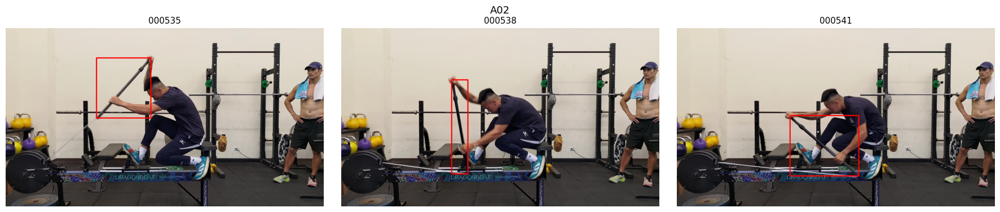

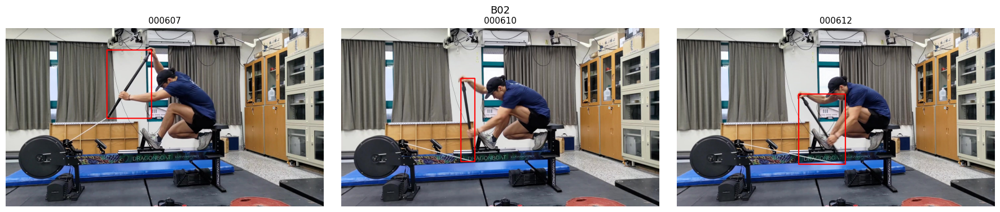

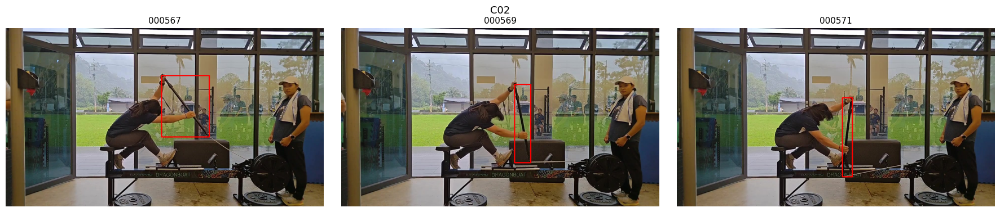

In [22]:
# 顯示每張圖片的 label，檢查數量是否正確 -> 輸出表
# 根據 show_list 中的影片，將每張圖片的 label 繪製出來並顯示

show_list = ["A02", "B02", "C02"]
size = 3    # 每部影片最多顯示幾張圖（上限 5，每部一列）
assert 1 <= size <= 5, "size 必須在 1 到 5 之間"
assert stats.video_id.isin(show_list).sum() == len(show_list), "show_list 中的影片不存在"

# 數量檢查：標註檔數 vs 選樣配額（sel.frames）
cnt = pd.DataFrame([dict(video_id=v,
                         expected=int(sel.frames[sel.video_id == v].iloc[0]),
                         labels=len(list(LABELS_DIR.glob(f"{v}_*.txt"))))
                    for v in show_list])
cnt["ok"] = cnt.expected == cnt.labels
display(cnt)

# 把 YOLO 框畫回圖上（標題只放 frame 編號，plot 不含中文）
for v in show_list:
    files = sorted(LABELS_DIR.glob(f"{v}_*.txt"))[:size]
    fig, axes = plt.subplots(1, len(files), figsize=(len(files) * 6, 3.8), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, f in zip(axes.flat, files):
        img = cv2.cvtColor(cv2.imread(str(FRAMES_DIR / v / f"{f.stem}.jpg")), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        for line in f.read_text().splitlines():
            _, x, y, bw, bh = map(float, line.split())
            cv2.rectangle(img, (int((x - bw / 2) * w), int((y - bh / 2) * h)),
                          (int((x + bw / 2) * w), int((y + bh / 2) * h)), (255, 0, 0), max(2, w // 300))
        ax.imshow(img)
        ax.set_title(f.stem.split("_")[1], fontsize=11)
    fig.suptitle(v, fontsize=13)
    fig.tight_layout()
    plt.show()

# 建立資料集

在人工篩選完 360 張圖片後，其中：
- 300 張作為訓練資料集合
- 60 張作為驗證資料集合
- 按影片切分，val 為 `VAL_IDS`（5 部、60 張），結果存 `split.csv`。
- 整理成 Ultralytics 的格式：`dataset/images/{train,val}`、`dataset/labels/{train,val}` 與 `data.yaml`。

In [23]:
display(attrs.head())

,video_id,scene,shirtless,special
0,A01,窗草地,False,False
1,A02,支架室內,False,False
2,A04,支架室內,False,False
3,A05,支架室內,False,False
4,A06,支架室內,False,False


In [35]:
# 按影片切分：val 5 部（三個場景都有、含 720p 與 1080p），其餘為 train
VAL_IDS = ["B15", "C02", "A05", "B11", "B02"]
DATASET_DIR = ROOT / "dataset"
SPLIT_CSV = ROOT / "split.csv"
DATA_YAML = ROOT / "data.yaml"

assert set(VAL_IDS) <= set(attrs.video_id)
split = attrs[["video_id"]].copy()
split["split"] = split.video_id.map(lambda v: "val" if v in VAL_IDS else "train")   # train or val
split.to_csv(SPLIT_CSV, index=False)
split_of = dict(zip(split.video_id, split.split))

# 重建：刪掉 .done 或者更改 VAL_IDS
labels = sorted(LABELS_DIR.glob("*.txt"))
tag = f"val={','.join(sorted(VAL_IDS))} n={len(labels)} bytes={sum(f.stat().st_size for f in labels)}"
done = DATASET_DIR / ".done"
if done.exists() and done.read_text() == tag:
    print("dataset/ 已是最新，跳過複製")
else:
    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)          # 只清自己產生的 dataset/
    for s in ("train", "val"):
        for sub in ("images", "labels"):
            (DATASET_DIR / sub / s).mkdir(parents=True)
    for f in labels:
        vid = f.stem.split("_")[0]
        s = split_of[vid]
        shutil.copy2(FRAMES_DIR / vid / f"{f.stem}.jpg", DATASET_DIR / "images" / s / f"{f.stem}.jpg")
        shutil.copy2(f, DATASET_DIR / "labels" / s / f.name)
    done.write_text(tag)

DATA_YAML.write_text(f"path: {DATASET_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: paddle\n")
print(DATA_YAML.read_text())

path: /content/drive/MyDrive/Colab Notebooks/大三專題_備選題目_車禍/dataset
train: images/train
val: images/val
names:
  0: paddle



In [25]:
# 檢查：圖片與標註一一對應、張數、各場景與解析度分布
rows = []
for s in ("train", "val"):
    imgs = {f.stem for f in (DATASET_DIR / "images" / s).glob("*.jpg")}
    lbls = {f.stem for f in (DATASET_DIR / "labels" / s).glob("*.txt")}
    assert imgs == lbls, s
    rows.append(dict(split=s, images=len(imgs), labels=len(lbls)))
display(pd.DataFrame(rows))
assert [r["images"] for r in rows] == [PER_SCENE * 3 - 60, 60]

info = pd.DataFrame(dict(video_id=[f.stem.split("_")[0] for f in LABELS_DIR.glob("*.txt")]))
info["split"] = info.video_id.map(split_of)
info = info.merge(attrs[["video_id", "scene", "shirtless"]]).merge(stats[["video_id", "height"]])
display(info.groupby(["split", "scene"]).size().unstack(fill_value=0))
display(info.groupby(["split", "height"]).size().unstack(fill_value=0))
print("沒上衣比例:", info.groupby("split").shirtless.mean().round(3).to_dict())

,split,images,labels
0,train,300,300
1,val,60,60


scene,支架室內,教室室內,窗草地
split,,,
train,102,102,96
val,18,18,24


height,720,1080
split,,
train,96,204
val,24,36


沒上衣比例: {'train': 0.223, 'val': 0.2}


# 訓練（Ultralytics YOLOv11s）

- 資料：`split.csv` 切分、`dataset/` 與 `data.yaml`；`yolo11s.pt`、`imgsz=640`、`epochs=100`、`batch=16`、`seed=42`。
- 使用 YOLOv11s pretrain weight 直接 train

In [36]:
!pip install -q ultralytics

In [27]:
import ultralytics
from ultralytics import YOLO, settings

settings.update({"sync": False})        # 關閉 Ultralytics 的匿名分析上傳
print("ultralytics:", ultralytics.__version__)

# Colab：Drive 讀小檔很慢，訓練前把 dataset 複製到本機磁碟（/content）
# 快取：copytree 會連 .done 一起複製，兩邊 .done 相同就代表 /content 已是最新（runtime 被回收後 /content 會清空，自然重複製）
if IN_COLAB:
    LOCAL_DATASET = Path("/content/dataset")
    if (LOCAL_DATASET / ".done").exists() and (LOCAL_DATASET / ".done").read_text() == (DATASET_DIR / ".done").read_text():
        print("/content/dataset 已是最新，跳過複製")
    else:
        shutil.rmtree(LOCAL_DATASET, ignore_errors=True)
        shutil.copytree(DATASET_DIR, LOCAL_DATASET)
    TRAIN_YAML = Path("/content/data.yaml")
else:
    LOCAL_DATASET, TRAIN_YAML = DATASET_DIR, DATA_YAML
TRAIN_YAML.write_text(f"path: {LOCAL_DATASET}\ntrain: images/train\nval: images/val\nnames:\n  0: paddle\n")
print(TRAIN_YAML.read_text())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics: 8.4.216
path: /content/dataset
train: images/train
val: images/val
names:
  0: paddle



In [28]:
# 基線：報告沒寫超參數，先用 Ultralytics 預設值（結果中標註為「推測的設定」）
RUNS_DIR = ROOT / "runs"
RUN_NAME = "baseline"
RESUME = False                           # Colab 中斷後改成 True，從 last.pt 續訓

if RESUME:
    model = YOLO(RUNS_DIR / RUN_NAME / "weights" / "last.pt")
    model.train(resume=True)
else:
    model = YOLO("yolo11s.pt")
    model.train(data=str(TRAIN_YAML), imgsz=640, epochs=100, batch=16,
                seed=SEED, deterministic=True,
                project=str(RUNS_DIR), name=RUN_NAME, exist_ok=True)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

In [29]:
# val 同時用來挑 best.pt，分數略偏樂觀，不是獨立的 test
best = YOLO(RUNS_DIR / RUN_NAME / "weights" / "best.pt")
m = best.val(data=str(TRAIN_YAML), split="val", imgsz=640,
            project=str(RUNS_DIR), name=RUN_NAME + "_val", exist_ok=True)   # val 的圖也存到 Drive
print(f"mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f} | P {m.box.mp:.3f} | R {m.box.mr:.3f}")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3929.4±1024.5 MB/s, size: 192.2 KB)
val: Scanning /content/dataset/labels/val.cache... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 14.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.2it/s 1.8s0.7s
                   all         60         60      0.992          1      0.995      0.897
Speed: 1.9ms preprocess, 5.9ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /content/drive/MyDrive/Colab Notebooks/大三專題_備選題目_車禍/runs/baseline_val
mAP50 0.995 | mAP50-95 0.897 | P 0.992 | R 1.000


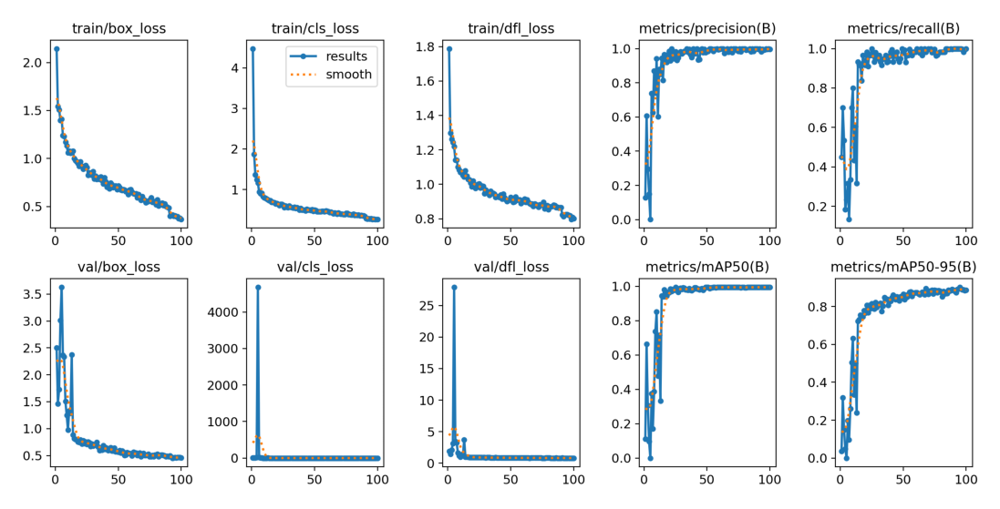

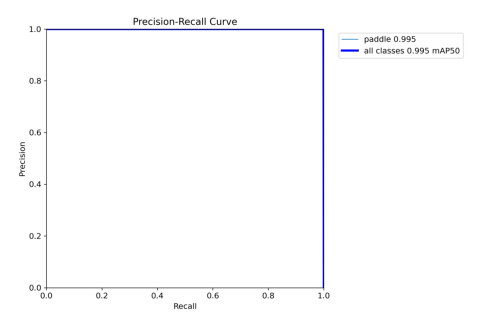

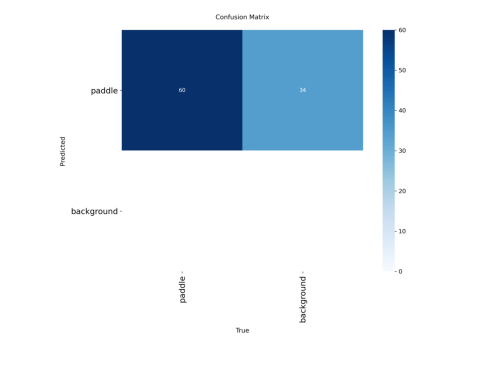

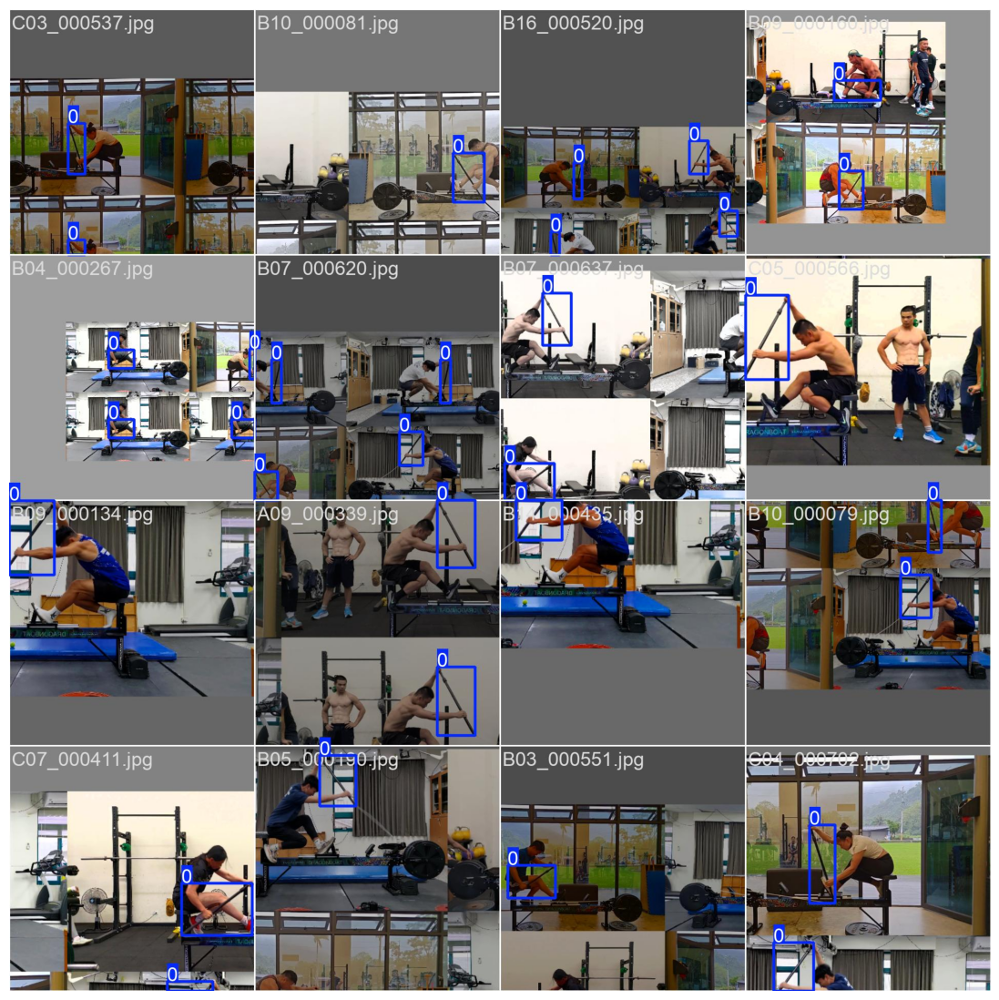

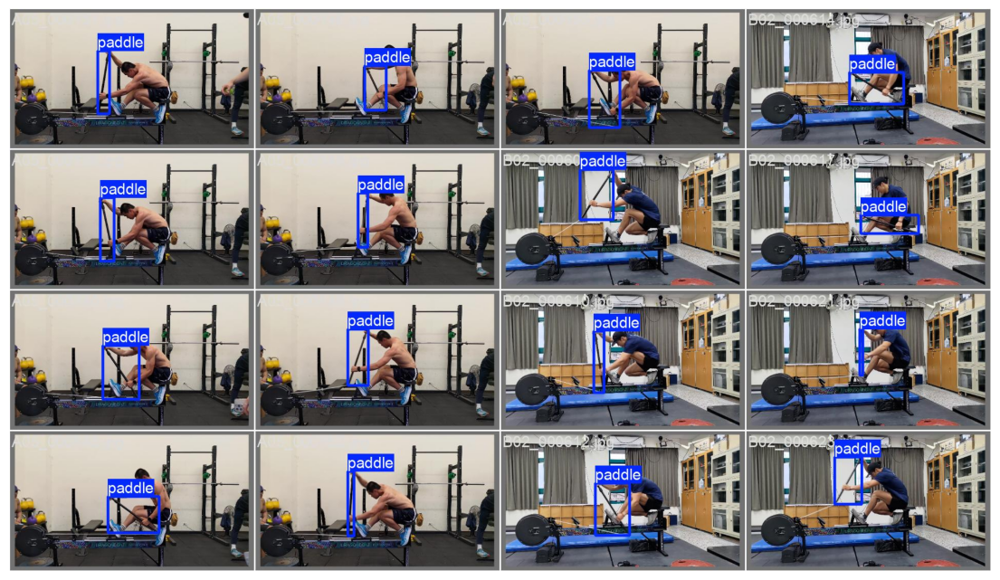

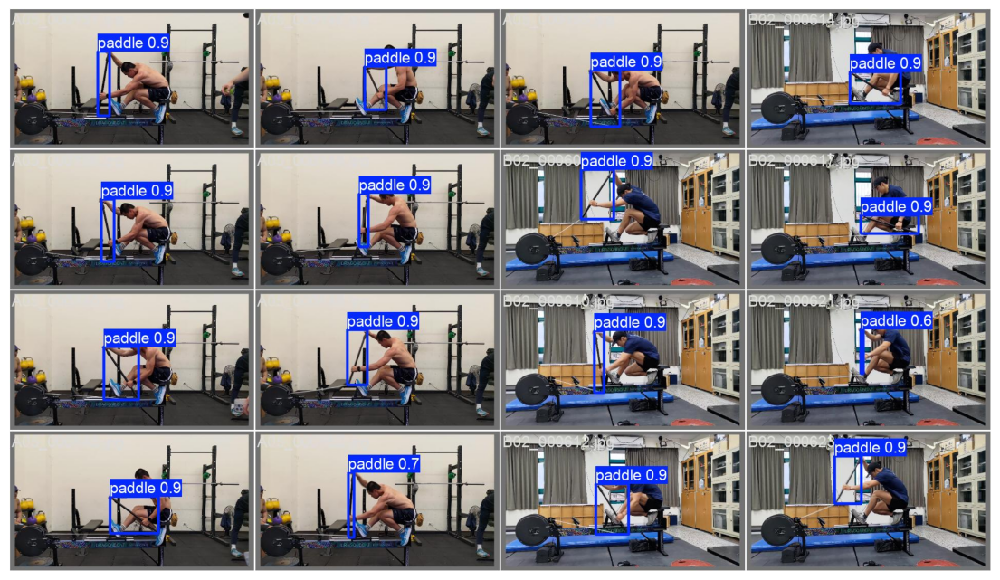

In [32]:
# 顯示 Ultralytics 輸出的圖（train_batch / val_batch 含人臉，分享前要 clear outputs）
from PIL import Image

val_dir = Path(m.save_dir)
figs = [(RUNS_DIR / RUN_NAME / "results.png", (14, 7)),
        (next(val_dir.glob("*PR_curve.png")), (6, 5)),            # 新版檔名可能帶 Box 前綴，用 glob 比對
        (next(val_dir.glob("*confusion_matrix.png")), (6, 5)),
        (RUNS_DIR / RUN_NAME / "train_batch0.jpg", (14, 14)),
        (val_dir / "val_batch0_labels.jpg", (14, 14)),      # 人工標註
        (val_dir / "val_batch0_pred.jpg", (14, 14))]        # 模型預測，與上一張對照
for path, size in figs:
    plt.figure(figsize=size)
    plt.imshow(Image.open(path))
    plt.axis("off")
    plt.show()